<a href="https://colab.research.google.com/github/razokiyassine/Network-Intrusion-Detection/blob/main/TP_Intrusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv('Test_data.csv')
print(df.shape)
df.head()

(22544, 41)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0,tcp,private,REJ,0,0,0,0,0,0,...,255,10,0.04,0.06,0.00,0.00,0.0,0.0,1.00,1.00
1,0,tcp,private,REJ,0,0,0,0,0,0,...,255,1,0.00,0.06,0.00,0.00,0.0,0.0,1.00,1.00
2,2,tcp,ftp_data,SF,12983,0,0,0,0,0,...,134,86,0.61,0.04,0.61,0.02,0.0,0.0,0.00,0.00
3,0,icmp,eco_i,SF,20,0,0,0,0,0,...,3,57,1.00,0.00,1.00,0.28,0.0,0.0,0.00,0.00
4,1,tcp,telnet,RSTO,0,15,0,0,0,0,...,29,86,0.31,0.17,0.03,0.02,0.0,0.0,0.83,0.71


In [11]:
print("Valeurs manquantes :", df.isnull().sum().sum())
print("Doublons :", df.duplicated().sum())

df = df.drop_duplicates()
df = df.drop(columns=['num_outbound_cmds'])

le = LabelEncoder()
for col in ['protocol_type', 'service', 'flag']:
    df[col] = le.fit_transform(df[col])

print("Nouvelles dimensions :", df.shape)
df.head()

Valeurs manquantes : 0
Doublons : 57
Nouvelles dimensions : (22487, 40)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0,1,45,1,0,0,0,0,0,0,...,255,10,0.04,0.06,0.00,0.00,0.0,0.0,1.00,1.00
1,0,1,45,1,0,0,0,0,0,0,...,255,1,0.00,0.06,0.00,0.00,0.0,0.0,1.00,1.00
2,2,1,19,9,12983,0,0,0,0,0,...,134,86,0.61,0.04,0.61,0.02,0.0,0.0,0.00,0.00
3,0,0,13,9,20,0,0,0,0,0,...,3,57,1.00,0.00,1.00,0.28,0.0,0.0,0.00,0.00
4,1,1,55,2,0,15,0,0,0,0,...,29,86,0.31,0.17,0.03,0.02,0.0,0.0,0.83,0.71


In [12]:
X_simple = df[['dst_host_serror_rate']]
y_simple = df['dst_host_srv_serror_rate']

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_simple, y_simple, test_size=0.2, random_state=42)

reg_simple = LinearRegression()
reg_simple.fit(X_train_s, y_train_s)

y_pred_s = reg_simple.predict(X_test_s)

print("Coefficient (a) :", reg_simple.coef_[0])
print("Intercept (b) :", reg_simple.intercept_)
print("R2 Score :", r2_score(y_test_s, y_pred_s))
print("MSE :", mean_squared_error(y_test_s, y_pred_s))
print("MAE :", mean_absolute_error(y_test_s, y_pred_s))

Coefficient (a) : 0.9765671395753505
Intercept (b) : 0.004517021672839808
R2 Score : 0.9062832531590053
MSE : 0.007371116082174028
MAE : 0.02211967091696693


In [13]:
X_multi = df.drop(columns=['dst_host_srv_serror_rate'])
y_multi = df['dst_host_srv_serror_rate']

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_m = scaler.fit_transform(X_train_m)
X_test_m = scaler.transform(X_test_m)

reg_multi = LinearRegression()
reg_multi.fit(X_train_m, y_train_m)

y_pred_m = reg_multi.predict(X_test_m)

print("R2 Score :", r2_score(y_test_m, y_pred_m))
print("MSE :", mean_squared_error(y_test_m, y_pred_m))
print("RMSE :", np.sqrt(mean_squared_error(y_test_m, y_pred_m)))
print("MAE :", mean_absolute_error(y_test_m, y_pred_m))

R2 Score : 0.9556591882931887
MSE : 0.003487543915958425
RMSE : 0.059055430876071215
MAE : 0.02478104401167289


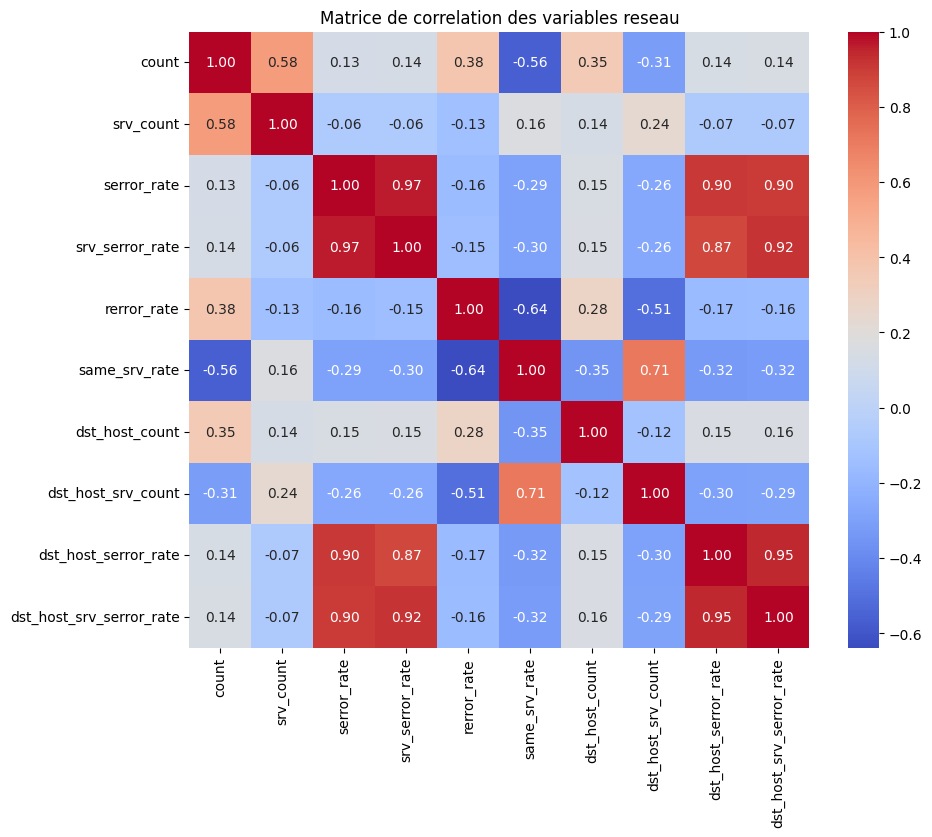

In [14]:
plt.figure(figsize=(10, 8))
cols = ['count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate',
        'same_srv_rate', 'dst_host_count', 'dst_host_srv_count',
        'dst_host_serror_rate', 'dst_host_srv_serror_rate']
sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matrice de correlation des variables reseau')
plt.show()

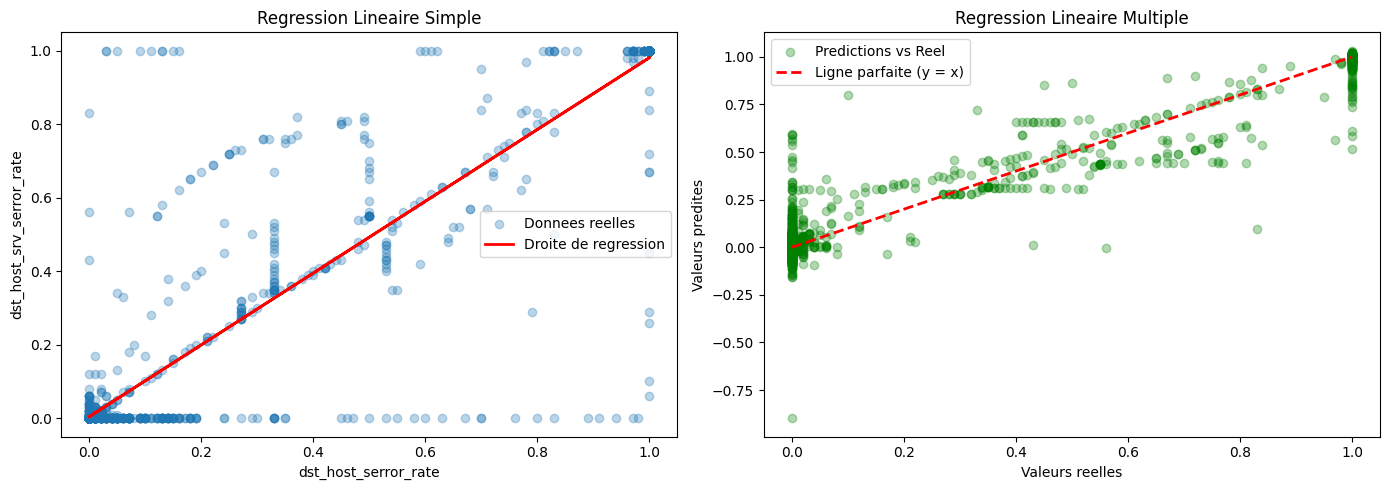

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_test_s, y_test_s, alpha=0.3, label='Donnees reelles')
axes[0].plot(X_test_s, y_pred_s, color='red', linewidth=2, label='Droite de regression')
axes[0].set_xlabel('dst_host_serror_rate')
axes[0].set_ylabel('dst_host_srv_serror_rate')
axes[0].set_title('Regression Lineaire Simple')
axes[0].legend()

axes[1].scatter(y_test_m, y_pred_m, alpha=0.3, color='green', label='Predictions vs Reel')
axes[1].plot([0, 1], [0, 1], color='red', linestyle='--', linewidth=2, label='Ligne parfaite (y = x)')
axes[1].set_xlabel('Valeurs reelles')
axes[1].set_ylabel('Valeurs predites')
axes[1].set_title('Regression Lineaire Multiple')
axes[1].legend()

plt.tight_layout()
plt.show()

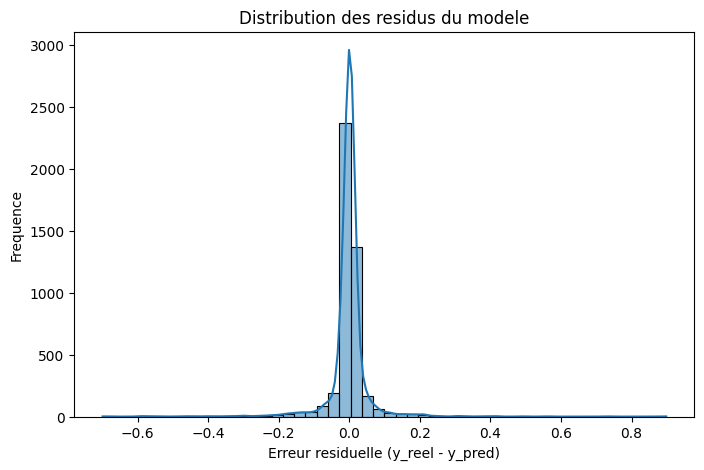

In [16]:
plt.figure(figsize=(8, 5))
residus = y_test_m - y_pred_m
sns.histplot(residus, bins=50, kde=True)
plt.xlabel('Erreur residuelle (y_reel - y_pred)')
plt.ylabel('Frequence')
plt.title('Distribution des residus du modele')
plt.show()